# Use a PyMC model

Write the generative model once, in PyMC. `elicito` reads the priors from
the PyMC model, learns their hyperparameters from the expert, and writes the
learned values back. The same PyMC model then fits the data with the
elicited priors.

The example is the linear regression of the tutorial
[Getting started with parametric priors][getting-started-with-parametric-priors].

> **Note:** the adapter needs Python 3.12 or later and the optional
> dependency `pymc`. Install it with `pip install "elicito[pymc]"`.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import joblib


def _warm() -> None:
    import elicito  # noqa: F401


joblib.Parallel(n_jobs=5)(joblib.delayed(_warm)() for _ in range(5))

import tensorflow as tf

tf.constant(0.0)

<tf.Tensor: shape=(), dtype=float32, numpy=0.0>

## Imports

In [2]:
from typing import Any

import arviz as az
import numpy as np
import pymc as pm
import tensorflow as tf
import tensorflow_probability as tfp

import elicito as el
from elicito.adapter import pymc as adapter_pymc

tfd = tfp.distributions

## The PyMC model

Follow these rules:

- Make each hyperparameter a named `pm.Data` node. Its name becomes the name
  of the hyperparameter in `elicito`.
- Use Normal, HalfNormal, Uniform, Beta or Gamma priors. A free random
  variable without a `pm.Data` input, such as a hierarchical effect, is not
  a prior: the generative model samples it.
- The likelihood and the operations can be those of the
  [case studies](../case-studies/index.md), for example Binomial,
  Categorical, Multinomial or MvNormal likelihoods, and indexing.
- Make the predictor and the data `pm.Data` nodes too. You can then replace
  them with `pm.set_data` before the fit.
- Do not give the likelihood a `shape` argument. It takes its shape from
  `observed`.

For the elicitation, the predictor holds the three design points of the
tutorial. The data are placeholders.

In [3]:
x_scaled = np.arange(30) / np.std(np.arange(30))
x_design = np.percentile(x_scaled, [25, 50, 75])

with pm.Model() as pymc_model:
    x = pm.Data("x", x_design)
    y_obs = pm.Data("y_obs", np.zeros(3))

    mu0, sigma0 = pm.Data("mu0", 0.0), pm.Data("sigma0", 1.0)
    mu1, sigma1 = pm.Data("mu1", 0.0), pm.Data("sigma1", 1.0)
    sigma2 = pm.Data("sigma2", 1.0)

    beta0 = pm.Normal("beta0", mu0, sigma0)
    beta1 = pm.Normal("beta1", mu1, sigma1)
    sigma = pm.HalfNormal("sigma", sigma2)

    epred = pm.Deterministic("epred", beta0 + beta1 * x)
    pm.Normal("ypred", epred, sigma, observed=y_obs)

## From PyMC to elicito

Give the PyMC model to `el.Elicit`. `elicito` reads the priors and
translates the model. The translated model returns every observed variable
and every `pm.Deterministic`, by name: here `ypred` and `epred`.

`adapter_pymc.parameters` shows the priors that `elicito` reads.

In [4]:
[(p["name"], p["family"].__name__) for p in adapter_pymc.parameters(pymc_model)]

[('beta0', 'Normal'), ('beta1', 'Normal'), ('sigma', 'HalfNormal')]

## Target quantities

The targets are those of the tutorial. `ypred` holds the outcome at the
three design points. `select=i` picks design point `i`. A target function
receives the model outputs by the names of its arguments.

In [5]:
def custom_r2(ypred: Any, epred: Any) -> Any:
    """Compute the coefficient of determination"""
    var_epred = tf.math.reduce_variance(epred, -1)
    var_diff = tf.math.reduce_variance(tf.subtract(ypred, epred), -1)
    return tf.divide(var_epred, var_epred + var_diff)


PROBS = (0.05, 0.25, 0.50, 0.75, 0.95)

targets = [
    *(
        el.quantiles(f"y_X{i}", output="ypred", select=i, probs=PROBS)
        for i in range(3)
    ),
    el.quantiles("R2", output=custom_r2, loss=el.losses.L2, weight=0.5),
]

## Expert and training

A simulated expert answers with the ground truth of the tutorial. CMA-ES
learns the hyperparameters. Five replications with different seeds show
whether the result depends on the seed.

In [6]:
ground_truth = {
    "beta0": tfd.Normal(loc=5, scale=1),
    "beta1": tfd.Normal(loc=2, scale=1),
    "sigma": tfd.HalfNormal(scale=7.0),
}

eliobj = el.Elicit(pymc_model, targets, seeds=(1, 2, 3, 4, 5), epochs=400)
fit = eliobj.fit(el.expert.simulator(ground_truth=ground_truth, num_samples=10_000))

Output()

`hyperparameters(replication=r)` returns the learned values of one
replication, by name. The true values are
`mu0=5, sigma0=1, mu1=2, sigma1=1, sigma2=7`.

In [7]:
for r in range(5):
    values = fit.hyperparameters(replication=r)
    print(r, {name: round(value, 2) for name, value in values.items()})

0 {'mu0': 4.98, 'mu1': 1.98, 'sigma0': 0.47, 'sigma1': 1.24, 'sigma2': 6.9}
1 {'mu0': 4.92, 'mu1': 2.0, 'sigma0': 0.0, 'sigma1': 1.25, 'sigma2': 6.96}
2 {'mu0': 5.05, 'mu1': 1.93, 'sigma0': 0.0, 'sigma1': 0.8, 'sigma2': 7.14}
3 {'mu0': 4.95, 'mu1': 1.99, 'sigma0': 1.55, 'sigma1': 0.96, 'sigma2': 6.94}
4 {'mu0': 4.94, 'mu1': 1.98, 'sigma0': 1.04, 'sigma1': 1.04, 'sigma2': 6.93}


## Back to PyMC

Replace the design points with the observed data. Here we simulate 50
observations.

In [8]:
n_obs = 50
x_data = np.arange(n_obs) / np.std(np.arange(n_obs))
rng = np.random.default_rng(2025)
y_data = 5.3 + 1.8 * x_data + rng.normal(0.0, 2.0, size=n_obs)

pm.set_data({"x": x_data, "y_obs": y_data}, model=pymc_model)

`set_hyperparameters` writes the learned values of one replication into the
`pm.Data` nodes. The priors of the PyMC model are then the elicited priors of
that replication. For each replication, we draw from the prior and fit the
model.

In [9]:
var_names = ["beta0", "beta1", "sigma"]
priors, posteriors = {}, {}
for r in range(5):
    adapter_pymc.set_hyperparameters(pymc_model, eliobj, replication=r)
    key = f"replication {r}"
    prior = pm.sample_prior_predictive(draws=2_000, random_seed=2025, model=pymc_model)
    # the same variable order as in the posterior plot
    prior["prior"] = prior["prior"].to_dataset()[var_names]
    priors[key] = prior
    posteriors[key] = pm.sample(
        draws=500,
        tune=500,
        chains=4,
        random_seed=2026,
        progressbar=False,
        model=pymc_model,
    )

Sampling: [beta0, beta1, sigma, ypred]


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [beta0, beta1, sigma]


Sampling 4 chains for 500 tune and 500 draw iterations (2_000 + 2_000 draws total) took 0 seconds.


Sampling: [beta0, beta1, sigma, ypred]


... (15 outputs left out)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [beta0, beta1, sigma]


Sampling 4 chains for 500 tune and 500 draw iterations (2_000 + 2_000 draws total) took 1 seconds.


The five elicited priors.

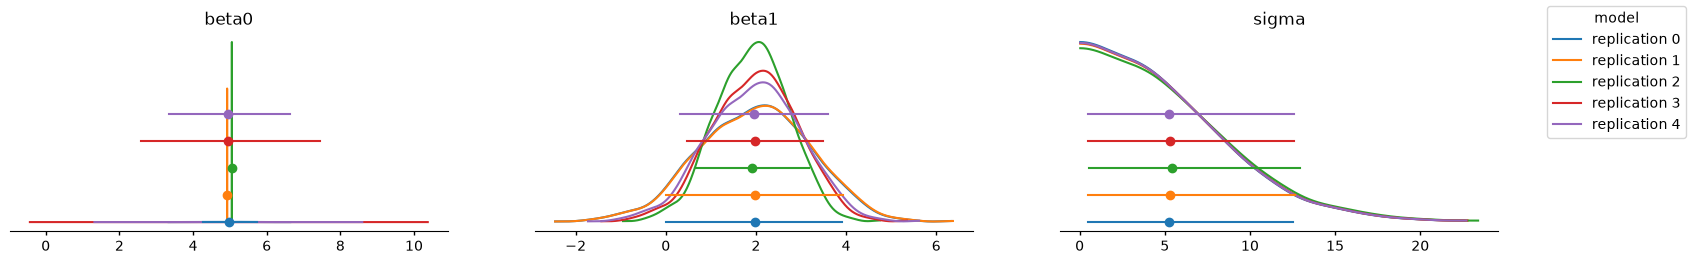

In [10]:
pc_prior = az.plot_dist(
    priors,
    group="prior",
    var_names=var_names,
    visuals={"point_estimate_text": False},
)
pc_prior.add_legend("model")

The posteriors of the five elicited priors.

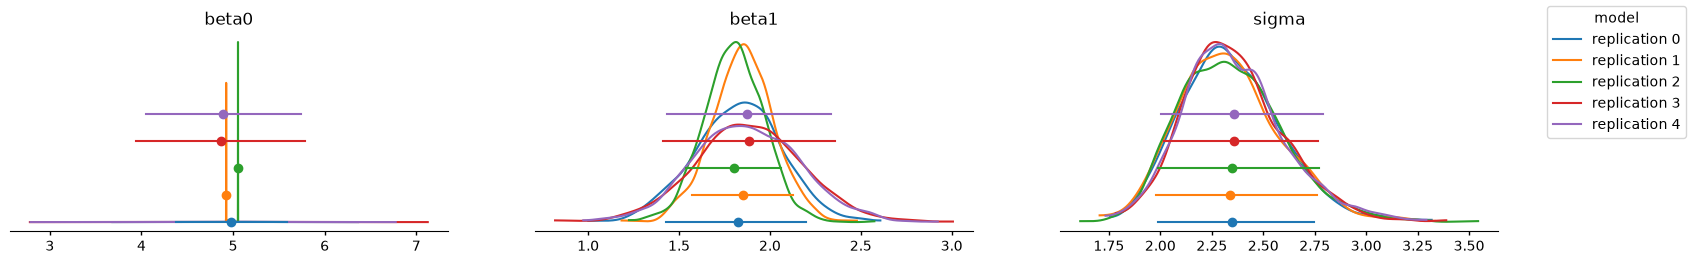

In [11]:
pc_posterior = az.plot_dist(
    posteriors,
    var_names=var_names,
    visuals={"point_estimate_text": False},
)
pc_posterior.add_legend("model")